# ML Assignment 2: Classification Models Comparison
## M.Tech (AIML) - Machine Learning

**Student Name:** PRAKASH B  
**Student ID:** 2026AJ05668
**Dataset:** EV Battery Health Prediction
**Submission Date:** 08-Nov-2026

---
## 1. Import Required Libraries
Import all necessary libraries for data manipulation, modeling, and evaluation

In [69]:
# Data manipulation libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize

# Classification models (5 required models)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import LinearSVC

# Evaluation metrics (6 required metrics)
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

# Model persistence
import joblib
import pickle
import os

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries imported successfully!")

All libraries imported successfully!


---
## 2. Load Dataset
Load your chosen classification dataset from Kaggle or UCI  
**Requirements:**
- Minimum 12 features
- Minimum 500 instances

In [51]:
# Load the EV battery health dataset from the same folder as this notebook.
df = pd.read_csv("ev_battery_health.csv")

# Display the dataset shape and first few rows.
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Dataset Shape: (50000, 35)

First 5 rows:


,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


---
## 3. Dataset Overview and Description
Provide comprehensive information about the dataset

In [52]:
# Display dataset information
print("Dataset Information:")
print("="*50)
df.info()

print("\n" + "="*50)
print("Dataset Statistics:")
print("="*50)
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   battery_id                      50000 non-null  object 
 1   observation_id                  50000 non-null  object 
 2   chemistry                       46541 non-null  object 
 3   manufacturer                    47539 non-null  object 
 4   vehicle_model                   46485 non-null  object 
 5   pack_capacity_kwh               47698 non-null  float64
 6   manufacture_date                48090 non-null  object 
 7   observation_date                47784 non-null  object 
 8   battery_age_days                46998 non-null  float64
 9   cycle_count                     47731 non-null  float64
 10  climate_zone                    47281 non-null  object 
 11  avg_daily_distance_km           47882 non-null  float64
 12  avg_chargin

,pack_capacity_kwh,battery_age_days,cycle_count,avg_daily_distance_km,avg_charging_power_kw,fast_charge_ratio,avg_depth_of_discharge_pct,avg_state_of_charge_pct,charge_cycles_per_month,total_energy_throughput_kwh,...,internal_resistance_mohm,voltage_avg_v,current_avg_a,charge_time_avg_min,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,recall_flag,state_of_health_pct,remaining_useful_life_cycles
count,47698.000000,46998.000000,47731.000000,47882.000000,47860.000000,46595.000000,47168.000000,46862.000000,47946.000000,46630.000000,...,47896.000000,47193.000000,47513.000000,47909.000000,47872.000000,48131.000000,48400.000000,47354.000000,50000.000000,50000.000000
mean,72.650524,561.185455,570.535292,50.171035,32.097005,0.294433,64.897098,67.560461,20.111044,38510.401641,...,49.209304,363.920232,137.766391,126.118169,26.627565,7.065756,1.428574,0.015226,92.935170,1491.181860
std,14.487910,479.605930,599.964295,39.456846,17.817125,0.172563,15.650667,10.073556,10.161119,42273.977765,...,21.311452,12.265127,20.017916,108.862722,12.914975,7.117441,1.674035,0.122451,7.115968,1213.873203
min,40.000000,1.000000,1.000000,3.000000,0.902804,0.000000,10.000000,30.900000,2.000000,36.400000,...,7.676580,318.500000,25.347077,5.471016,-10.903885,0.000000,0.000000,0.000000,55.000000,0.000000
25%,62.500000,169.000000,137.000000,22.500000,19.100000,0.162000,54.100000,60.700000,12.600000,8857.725000,...,34.840000,355.200000,125.100000,61.000000,17.800000,1.950000,0.000000,0.000000,90.080000,600.000000
50%,72.600000,424.000000,371.000000,39.300000,28.800000,0.272000,65.100000,67.800000,18.900000,24134.400000,...,43.080000,365.600000,137.300000,94.400000,26.800000,4.800000,1.000000,0.000000,95.200000,1142.000000
75%,82.800000,846.000000,801.000000,66.100000,42.000000,0.407000,75.900000,74.600000,26.400000,53339.400000,...,56.992500,373.000000,150.100000,150.400000,35.600000,9.930000,2.000000,0.000000,98.050000,2322.000000
max,100.000000,2184.000000,5073.000000,400.000000,159.640602,0.939000,100.000000,95.000000,57.500000,402419.900000,...,307.090497,402.800000,291.815646,1232.429212,93.640098,45.000000,15.000000,1.000000,100.000000,5928.000000


In [53]:
# Check for missing values
print("Missing Values:")
print("="*50)
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

# If no missing values
if missing_values.sum() == 0:
    print("No missing values found!")

Missing Values:
chemistry                          3459
manufacturer                       2461
vehicle_model                      3515
pack_capacity_kwh                  2302
manufacture_date                   1910
observation_date                   2216
battery_age_days                   3002
cycle_count                        2269
climate_zone                       2719
avg_daily_distance_km              2118
avg_charging_power_kw              2140
fast_charge_ratio                  3405
avg_depth_of_discharge_pct         2832
avg_state_of_charge_pct            3138
charge_cycles_per_month            2054
total_energy_throughput_kwh        3370
avg_ambient_temp_c                 3282
humidity_pct                       2737
altitude_m                         2322
internal_resistance_mohm           2104
voltage_avg_v                      2807
current_avg_a                      2487
charge_time_avg_min                2091
peak_temp_during_fast_charge_c     2128
capacity_fade_pct       

Target Variable Distribution:
failure_risk_label
Low       42735
Medium     4409
High       2856
Name: count, dtype: int64


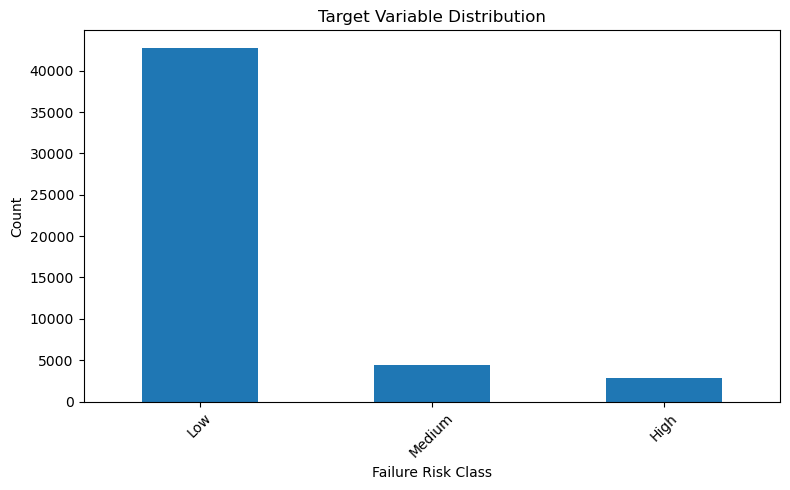

In [54]:
# Select the near-term battery failure risk classification target.
target_column = "failure_risk_label"

# Check target variable distribution.
print("Target Variable Distribution:")
print("=" * 50)
print(df[target_column].value_counts())

# Visualize the target distribution.
plt.figure(figsize=(8, 5))
df[target_column].value_counts().plot(kind="bar")
plt.title("Target Variable Distribution")
plt.xlabel("Failure Risk Class")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---
## 4. Exploratory Data Analysis (EDA)
Visualize and understand the data better

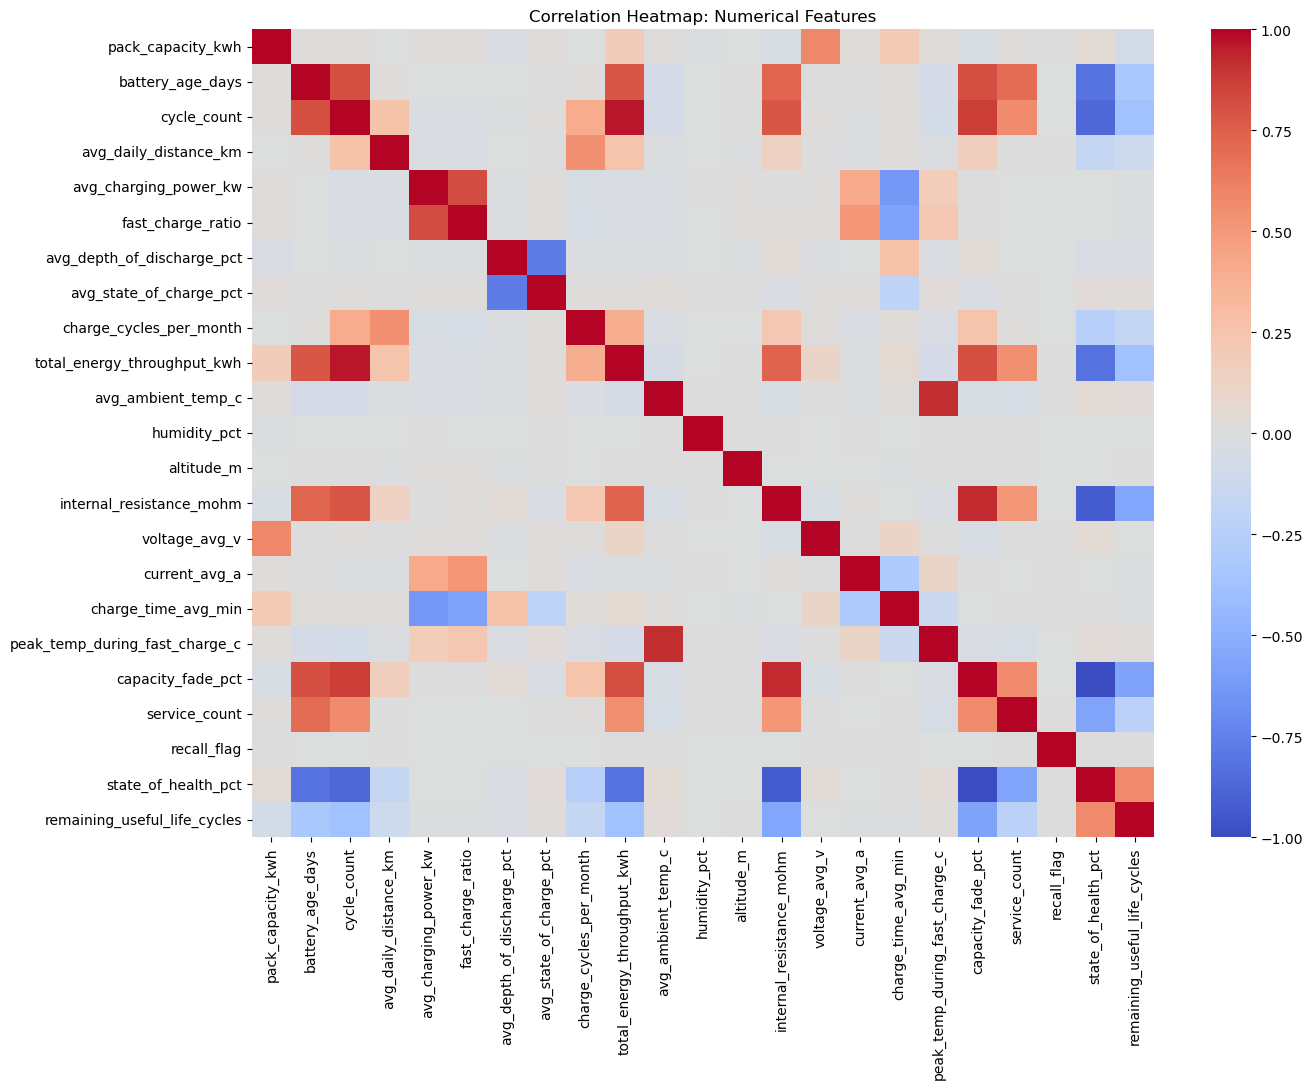

In [55]:
# Correlation heatmap for numerical features only.
numeric_features = df.select_dtypes(include=np.number)
correlation_matrix = numeric_features.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap: Numerical Features")
plt.tight_layout()
plt.show()

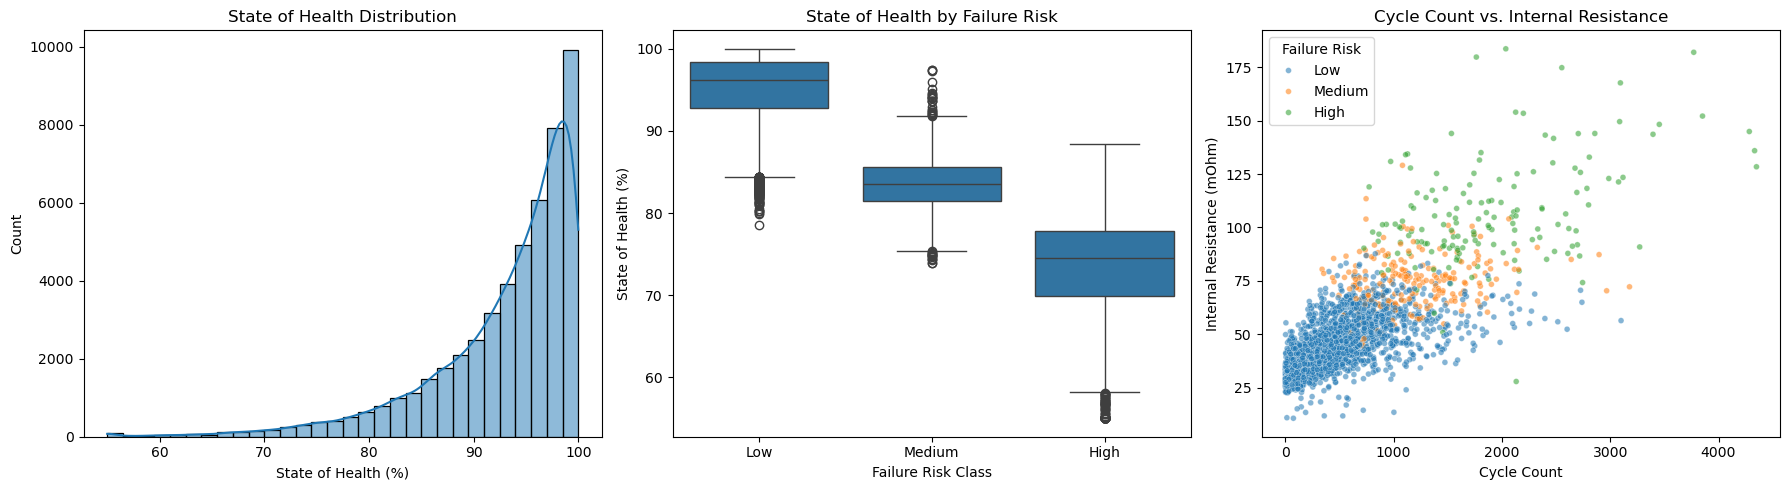

In [56]:
# Explore battery health and its relationship to failure risk.
risk_order = ["Low", "Medium", "High"]
plot_sample = df.sample(n=min(3000, len(df)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["state_of_health_pct"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("State of Health Distribution")
axes[0].set_xlabel("State of Health (%)")

sns.boxplot(
    data=df,
    x=target_column,
    y="state_of_health_pct",
    order=risk_order,
    ax=axes[1]
)
axes[1].set_title("State of Health by Failure Risk")
axes[1].set_xlabel("Failure Risk Class")
axes[1].set_ylabel("State of Health (%)")

sns.scatterplot(
    data=plot_sample,
    x="cycle_count",
    y="internal_resistance_mohm",
    hue=target_column,
    hue_order=risk_order,
    alpha=0.55,
    s=18,
    ax=axes[2]
)
axes[2].set_title("Cycle Count vs. Internal Resistance")
axes[2].set_xlabel("Cycle Count")
axes[2].set_ylabel("Internal Resistance (mOhm)")
axes[2].legend(title="Failure Risk")

plt.tight_layout()
plt.show()

---
## 5. Data Preprocessing
Handle missing values, encode categorical variables, and prepare features

In [63]:
# Remove identifiers, raw dates, and alternative target columns to prevent leakage.
columns_to_drop = [
    "battery_id",
    "observation_id",
    "manufacture_date",
    "observation_date",
    "last_service_date",
    "state_of_health_pct",
    "remaining_useful_life_cycles",
    "degradation_category",
]
df = df.drop(columns=columns_to_drop, errors="ignore")

# Rows without a target cannot be used for supervised classification.
missing_target_count = df[target_column].isna().sum()
if missing_target_count:
    df = df.dropna(subset=[target_column]).copy()

# Impute numeric features with medians and categorical features with an explicit category.
numeric_feature_cols = df.select_dtypes(include=np.number).columns.drop(
    target_column, errors="ignore"
)
categorical_feature_cols = df.select_dtypes(
    include=["object", "category"]
).columns.drop(target_column, errors="ignore")

df[numeric_feature_cols] = df[numeric_feature_cols].fillna(
    df[numeric_feature_cols].median()
)
df[categorical_feature_cols] = df[categorical_feature_cols].fillna("Unknown")

print(f"Rows removed for missing target: {missing_target_count}")
print(f"Missing values remaining: {int(df.isna().sum().sum())}")

Rows removed for missing target: 0
Missing values remaining: 0


In [64]:
# One-hot encode categorical features while keeping the target separate.
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
if target_column in categorical_cols:
    categorical_cols.remove(target_column)

df = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)

feature_cols = df.columns.drop(target_column)
non_numeric_features = df[feature_cols].select_dtypes(exclude=np.number).columns.tolist()
if non_numeric_features:
    raise TypeError(f"Non-numeric features remain: {non_numeric_features}")

print(f"One-hot encoded {len(categorical_cols)} categorical feature columns.")
print(f"Preprocessed feature count: {len(feature_cols)}")

One-hot encoded 5 categorical feature columns.
Preprocessed feature count: 51


In [65]:
# Encode the classification target and save its class mapping for later predictions.
if df[target_column].isna().any():
    raise ValueError(f"Target column '{target_column}' contains missing values.")

if not pd.api.types.is_numeric_dtype(df[target_column]):
    le_target = LabelEncoder()
    df[target_column] = le_target.fit_transform(df[target_column].astype(str))
    joblib.dump(le_target, "target_label_encoder.pkl")
    print(f"Target classes: {dict(enumerate(le_target.classes_))}")
else:
    print(f"Target column '{target_column}' is already encoded.")

print(f"Target dtype: {df[target_column].dtype}")

Target column 'failure_risk_label' is already encoded.
Target dtype: int64


---
## 6. Feature Selection and Target Separation
Separate features (X) and target (y)

In [66]:
# Separate features and target
X = df.drop(columns=[target_column])
y = df[target_column]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"\nNumber of features: {X.shape[1]}")
print(f"Number of samples: {X.shape[0]}")
print(f"Number of classes: {y.nunique()}")

Features shape: (50000, 51)
Target shape: (50000,)

Number of features: 51
Number of samples: 50000
Number of classes: 3


---
## 7. Train-Test Split
Split data into training and testing sets (80-20 or 70-30 split)

In [67]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,  # 80-20 split
    random_state=RANDOM_STATE,
    stratify=y  # Maintains class distribution
)

print(f"Training set size: {X_train.shape[0]}")
print(f"Testing set size: {X_test.shape[0]}")
print(f"\nTraining set class distribution:")
print(y_train.value_counts())
print(f"\nTesting set class distribution:")
print(y_test.value_counts())

Training set size: 40000
Testing set size: 10000

Training set class distribution:
failure_risk_label
1    34188
2     3527
0     2285
Name: count, dtype: int64

Testing set class distribution:
failure_risk_label
1    8547
2     882
0     571
Name: count, dtype: int64


---
## 8. Feature Scaling
Standardize features for models that are sensitive to feature scales (KNN, SVM, Logistic Regression)

In [68]:
# Standardize features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save the scaler for later use in Streamlit app
joblib.dump(scaler, 'scaler.pkl')

print("Feature scaling completed!")
print(f"Scaled training set shape: {X_train_scaled.shape}")
print(f"Scaled testing set shape: {X_test_scaled.shape}")

Feature scaling completed!
Scaled training set shape: (40000, 51)
Scaled testing set shape: (10000, 51)


---
## 9. Save Test Data for Streamlit App
Save test data as CSV for uploading to Streamlit app

In [82]:
# Create test data CSV with features and target
test_data = pd.DataFrame(X_test, columns=X.columns)
test_data[target_column] = y_test.values

# Save to CSV
test_data.to_csv('test_data.csv', index=False)
print("Test data saved as 'test_data.csv'")
print(f"Test data shape: {test_data.shape}")

Test data saved as 'test_data.csv'
Test data shape: (10000, 52)


---
## 10. Model Training and Evaluation Function
Create a reusable function to train models and calculate all 6 required metrics

In [80]:
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name):
    """Train a classifier and report the six required evaluation metrics."""
    print(f"\n{'=' * 60}")
    print(f"Training {model_name}...")
    print(f"{'=' * 60}")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    try:
        if hasattr(model, "predict_proba"):
            y_scores = model.predict_proba(X_test)
            if len(model.classes_) == 2:
                auc_score = roc_auc_score(y_test, y_scores[:, 1])
            else:
                auc_score = roc_auc_score(
                    y_test, y_scores, multi_class="ovr", average="weighted"
                )
        elif hasattr(model, "decision_function"):
            y_scores = model.decision_function(X_test)
            if len(model.classes_) == 2:
                if y_scores.ndim == 2:
                    y_scores = y_scores[:, 1]
                auc_score = roc_auc_score(y_test, y_scores)
            else:
                y_test_binary = label_binarize(y_test, classes=model.classes_)
                auc_score = roc_auc_score(
                    y_test_binary, y_scores, average="weighted"
                )
        else:
            auc_score = np.nan
    except (AttributeError, ValueError) as error:
        print(f"AUC could not be calculated: {error}")
        auc_score = np.nan

    precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)

    results = {
        "Model": model_name,
        "Accuracy": round(accuracy, 4),
        "AUC": round(auc_score, 4) if not np.isnan(auc_score) else np.nan,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1": round(f1, 4),
        "MCC": round(mcc, 4),
    }

    print("\nEvaluation Metrics:")
    for metric, value in results.items():
        if metric != "Model":
            print(f"{metric:12s}: {value:.4f}" if pd.notna(value) else f"{metric:12s}: N/A")

    labels = model.classes_
    class_names = [str(label) for label in le_target.classes_]
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

    print(f"\nClassification Report for {model_name}:")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=labels,
            target_names=class_names,
            zero_division=0,
        )
    )

    return results, model

---
## 11. Model 1: Logistic Regression
Train and evaluate Logistic Regression model


Training Logistic Regression...

Evaluation Metrics:
Accuracy    : 0.9493
AUC         : 0.9886
Precision   : 0.9486
Recall      : 0.9493
F1          : 0.9488
MCC         : 0.7999


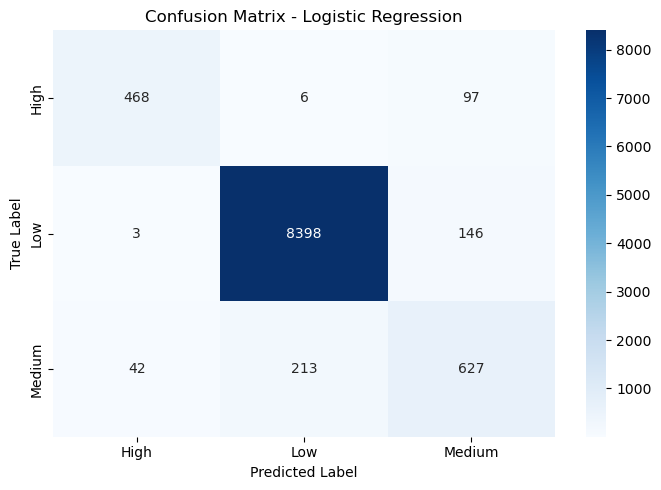


Classification Report for Logistic Regression:
              precision    recall  f1-score   support

        High       0.91      0.82      0.86       571
         Low       0.97      0.98      0.98      8547
      Medium       0.72      0.71      0.72       882

    accuracy                           0.95     10000
   macro avg       0.87      0.84      0.85     10000
weighted avg       0.95      0.95      0.95     10000



In [81]:
# Initialize Logistic Regression model
# Use scaled data for better performance
lr_model = LogisticRegression(
    random_state=RANDOM_STATE,
    max_iter=1000,  # Increase iterations for convergence
    n_jobs=-1  # Use all CPU cores
)

# Train and evaluate
lr_results, lr_trained = evaluate_model(
    lr_model, 
    X_train_scaled, 
    X_test_scaled, 
    y_train, 
    y_test, 
    'Logistic Regression'
)

In [89]:
# Save the trained model
os.makedirs('model', exist_ok=True)
joblib.dump(lr_trained, 'model/logistic_regression.pkl')
print("Logistic Regression model saved!")

Logistic Regression model saved!


---
## 12. Model 2: Decision Tree Classifier
Train and evaluate Decision Tree model


Training Decision Tree...

Evaluation Metrics:
Accuracy    : 0.9458
AUC         : 0.9560
Precision   : 0.9456
Recall      : 0.9458
F1          : 0.9457
MCC         : 0.7884


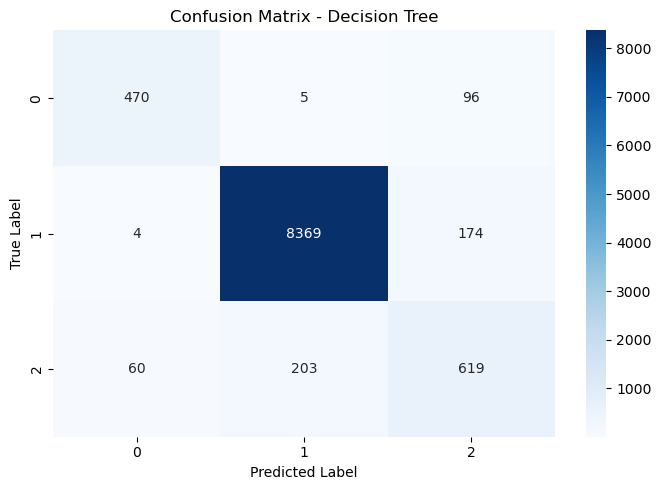


Classification Report for Decision Tree:
              precision    recall  f1-score   support

           0       0.88      0.82      0.85       571
           1       0.98      0.98      0.98      8547
           2       0.70      0.70      0.70       882

    accuracy                           0.95     10000
   macro avg       0.85      0.83      0.84     10000
weighted avg       0.95      0.95      0.95     10000



In [74]:
# Initialize Decision Tree Classifier
# Decision Trees don't require scaled data
dt_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
    max_depth=10,  # Prevent overfitting
    min_samples_split=5,
    min_samples_leaf=2
)

# Train and evaluate
dt_results, dt_trained = evaluate_model(
    dt_model, 
    X_train,  # Use unscaled data
    X_test, 
    y_train, 
    y_test, 
    'Decision Tree'
)

In [75]:
# Save the trained model
joblib.dump(dt_trained, 'model/decision_tree.pkl')
print("Decision Tree model saved!")

Decision Tree model saved!


---
## 13. Model 3: K-Nearest Neighbors (KNN) Classifier
Train and evaluate KNN model


Training K-Nearest Neighbors...

Evaluation Metrics:
Accuracy    : 0.9042
AUC         : 0.9297
Precision   : 0.8844
Recall      : 0.9042
F1          : 0.8886
MCC         : 0.5729


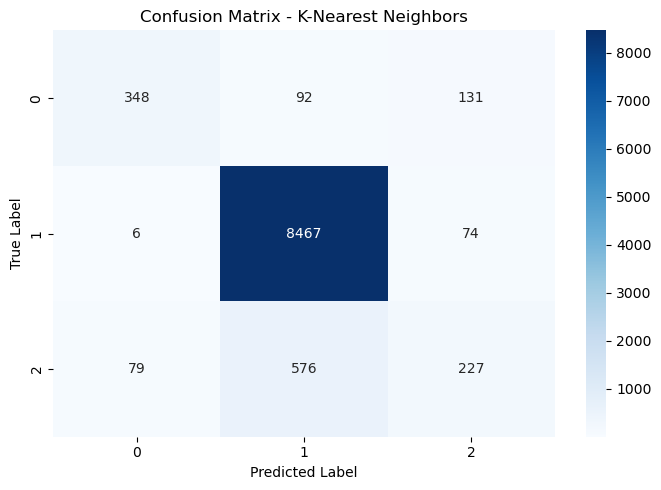


Classification Report for K-Nearest Neighbors:
              precision    recall  f1-score   support

           0       0.80      0.61      0.69       571
           1       0.93      0.99      0.96      8547
           2       0.53      0.26      0.35       882

    accuracy                           0.90     10000
   macro avg       0.75      0.62      0.67     10000
weighted avg       0.88      0.90      0.89     10000



In [76]:
# Initialize KNN Classifier
# KNN requires scaled data for better performance
knn_model = KNeighborsClassifier(
    n_neighbors=5,  # Default value, can be tuned
    weights='uniform',  # or 'distance'
    n_jobs=-1  # Use all CPU cores
)

# Train and evaluate
knn_results, knn_trained = evaluate_model(
    knn_model, 
    X_train_scaled, 
    X_test_scaled, 
    y_train, 
    y_test, 
    'K-Nearest Neighbors'
)

In [77]:
# Save the trained model
joblib.dump(knn_trained, 'model/knn.pkl')
print("KNN model saved!")

KNN model saved!


---
## 14. Model 4: Naive Bayes Classifier
Train and evaluate Naive Bayes model (Gaussian or Multinomial)


Training Naive Bayes...

Evaluation Metrics:
Accuracy    : 0.8913
AUC         : 0.9767
Precision   : 0.9350
Recall      : 0.8913
F1          : 0.9054
MCC         : 0.6826


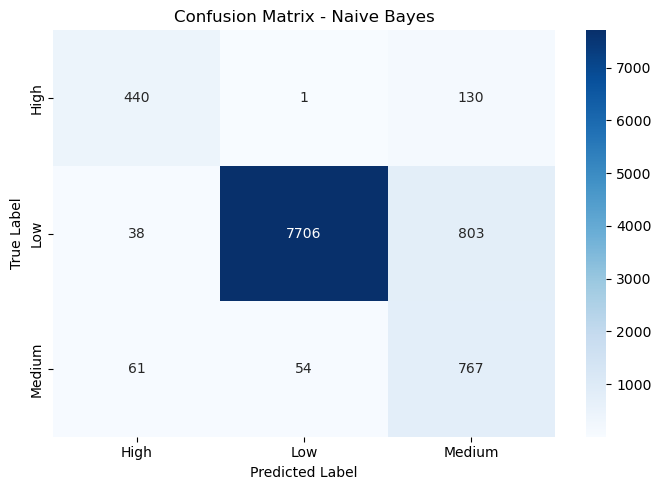


Classification Report for Naive Bayes:
              precision    recall  f1-score   support

        High       0.82      0.77      0.79       571
         Low       0.99      0.90      0.95      8547
      Medium       0.45      0.87      0.59       882

    accuracy                           0.89     10000
   macro avg       0.75      0.85      0.78     10000
weighted avg       0.94      0.89      0.91     10000



In [84]:
# GaussianNB is suitable for the continuous battery telemetry features.
nb_model = GaussianNB()

# Train and evaluate using scaled features.
nb_results, nb_trained = evaluate_model(
    nb_model,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test,
    "Naive Bayes"
)

In [90]:
# Save the trained model
joblib.dump(nb_trained, 'model/naive_bayes.pkl')
print("Naive Bayes model saved!")

Naive Bayes model saved!


---
## 15. Model 5: Support Vector Machine (SVM)
Train and evaluate SVM model


Training Support Vector Machine...

Evaluation Metrics:
Accuracy    : 0.9365
AUC         : 0.9831
Precision   : 0.9332
Recall      : 0.9365
F1          : 0.9261
MCC         : 0.7363


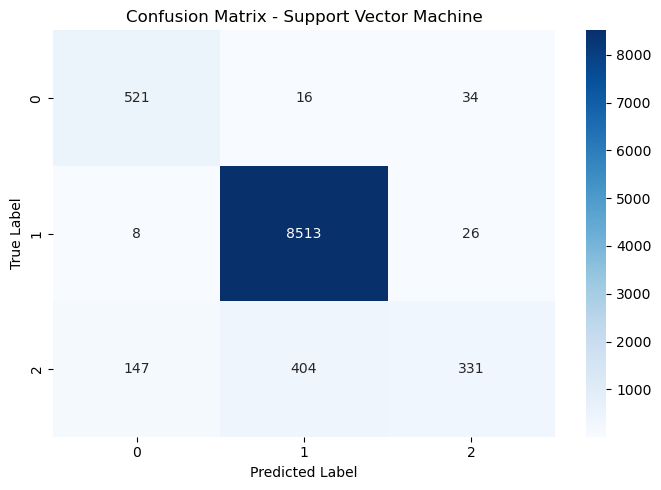


Classification Report for Support Vector Machine:
              precision    recall  f1-score   support

           0       0.77      0.91      0.84       571
           1       0.95      1.00      0.97      8547
           2       0.85      0.38      0.52       882

    accuracy                           0.94     10000
   macro avg       0.86      0.76      0.78     10000
weighted avg       0.93      0.94      0.93     10000



In [79]:
# Linear SVM is suitable for the 40,000-row training set.
svm_model = LinearSVC(
    random_state=RANDOM_STATE,
    dual="auto",
    max_iter=5000
)

# Train and evaluate using scaled features.
svm_results, svm_trained = evaluate_model(
    svm_model,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test,
    "Support Vector Machine"
)

In [88]:
# Save the trained model
joblib.dump(svm_trained, 'model/svm.pkl')
print("SVM model saved!")

SVM model saved!


---
## 16. Comprehensive Model Comparison
Create comparison table with all metrics for all 5 models

In [85]:
# Combine all results into a comparison dataframe
comparison_df = pd.DataFrame([
    lr_results,
    dt_results,
    knn_results,
    nb_results,
    svm_results
])

# Display the comparison table
print("\n" + "="*80)
print("MODEL COMPARISON TABLE")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)

# Save to CSV
comparison_df.to_csv('model_comparison.csv', index=False)
print("\nComparison table saved as 'model_comparison.csv'")


MODEL COMPARISON TABLE
                 Model  Accuracy    AUC  Precision  Recall     F1    MCC
   Logistic Regression    0.9493 0.9886     0.9486  0.9493 0.9488 0.7999
         Decision Tree    0.9458 0.9560     0.9456  0.9458 0.9457 0.7884
   K-Nearest Neighbors    0.9042 0.9297     0.8844  0.9042 0.8886 0.5729
           Naive Bayes    0.8913 0.9767     0.9350  0.8913 0.9054 0.6826
Support Vector Machine    0.9365 0.9831     0.9332  0.9365 0.9261 0.7363

Comparison table saved as 'model_comparison.csv'


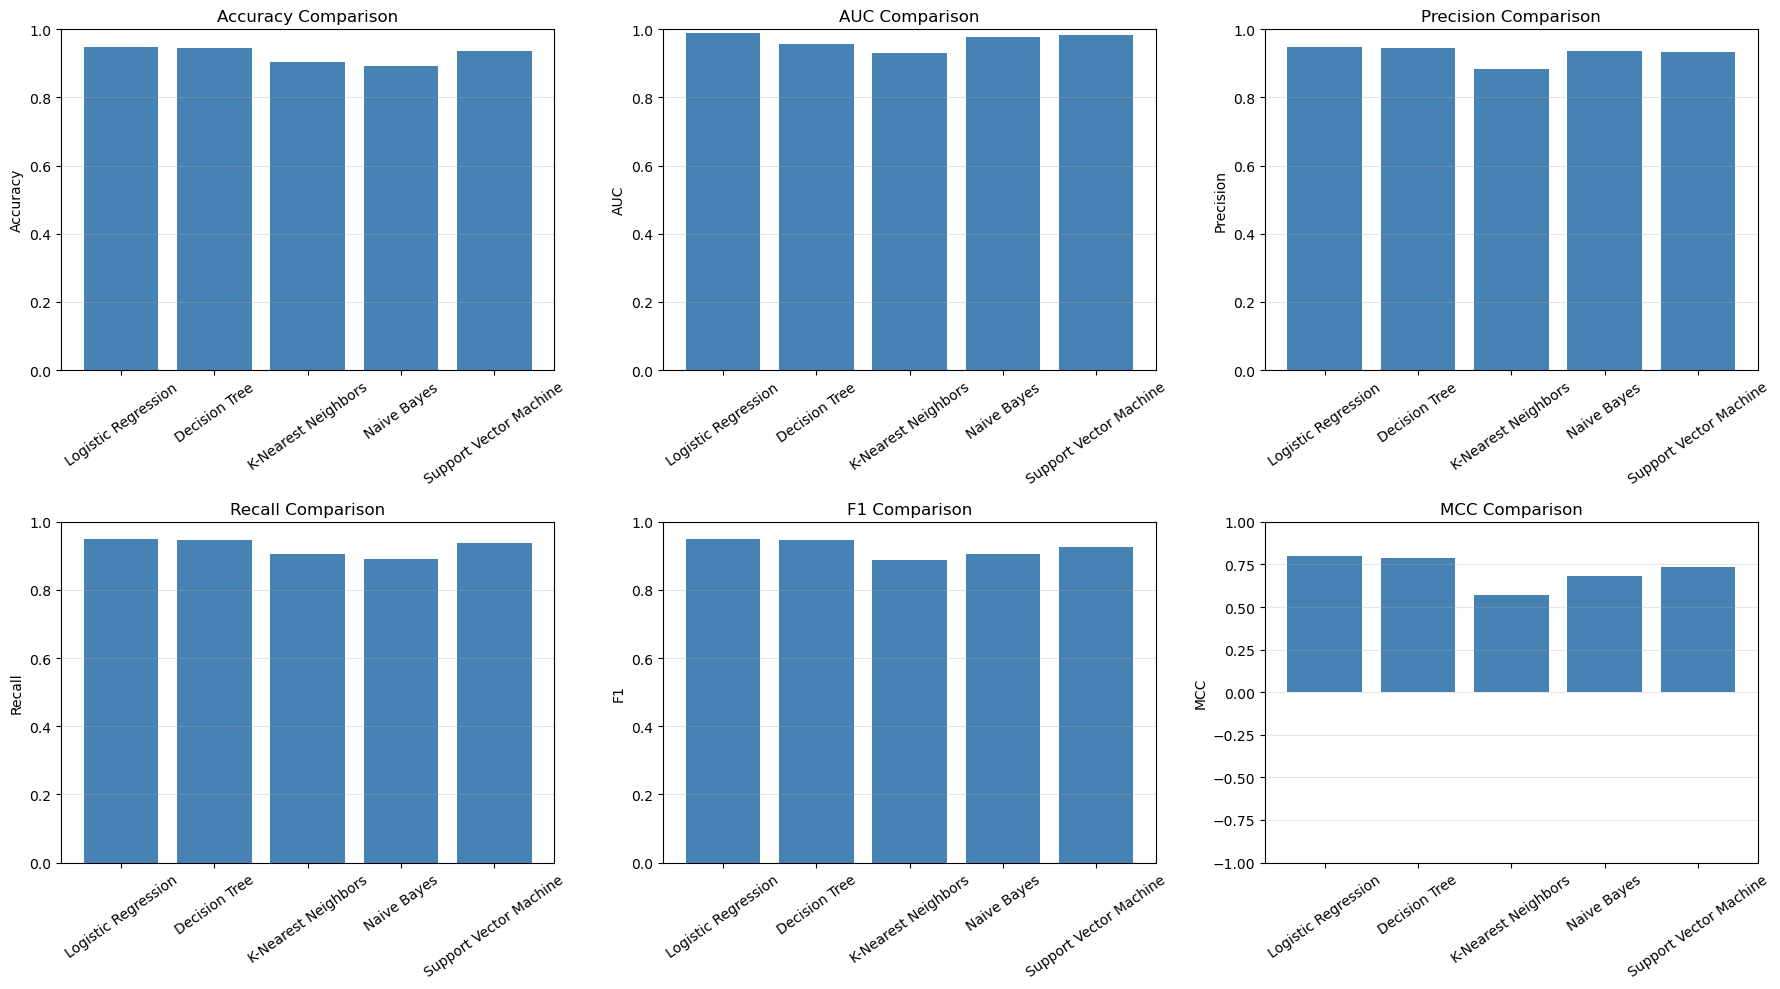

Comparison plot saved as 'model_comparison.png'


In [86]:
# Compare all six required evaluation metrics across the five classifiers.
metrics_to_plot = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for axis, metric in zip(axes.flat, metrics_to_plot):
    axis.bar(comparison_df["Model"], comparison_df[metric], color="steelblue")
    axis.set_title(f"{metric} Comparison")
    axis.set_ylabel(metric)
    axis.tick_params(axis="x", rotation=35)
    axis.grid(axis="y", alpha=0.3)
    axis.set_ylim((-1, 1) if metric == "MCC" else (0, 1))

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
print("Comparison plot saved as 'model_comparison.png'")

---
## 17. Model Performance Observations
Analyze and document observations about each model

In [87]:
# Identify top performers and rank models across all six required metrics.
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]

print("Best Performing Models:")
print("=" * 60)
for metric in metric_columns:
    best_idx = comparison_df[metric].idxmax()
    print(
        f"{metric:12s}: {comparison_df.loc[best_idx, 'Model']} "
        f"({comparison_df.loc[best_idx, metric]:.4f})"
    )

comparison_df["Average_Rank"] = comparison_df[metric_columns].rank(
    ascending=False, method="average"
).mean(axis=1)
winner_idx = comparison_df["Average_Rank"].idxmin()
winner = comparison_df.loc[winner_idx, "Model"]

print("\nOverall winner by average rank across six metrics:")
print(f"{winner} (average rank {comparison_df.loc[winner_idx, 'Average_Rank']:.2f})")

Best Performing Models:
Accuracy    : Logistic Regression (0.9493)
AUC         : Logistic Regression (0.9886)
Precision   : Logistic Regression (0.9486)
Recall      : Logistic Regression (0.9493)
F1          : Logistic Regression (0.9488)
MCC         : Logistic Regression (0.7999)

Overall winner by average rank across six metrics:
Logistic Regression (average rank 1.00)


## Model Performance Observations

The target classes are imbalanced, with Low risk comprising most observations. Weighted metrics therefore summarize overall performance, while class-level reports show how well each model identifies High- and Medium-risk batteries.

| Model | Observation |
|---|---|
| Logistic Regression | Best overall: accuracy 0.9493, AUC 0.9886, weighted F1 0.9488, and MCC 0.7999. It performs strongly on Low risk and has the best balance across the aggregate metrics, though Medium-risk recall is 0.71. |
| Decision Tree | Accuracy 0.9458 and weighted F1 0.9457 are close to Logistic Regression, with MCC 0.7884. It is interpretable and gives balanced class-level results, but its AUC (0.9560) is lower than the other leading models. |
| K-Nearest Neighbors | Lowest overall results among the five: accuracy 0.9042, weighted F1 0.8886, and MCC 0.5729. It identifies the majority Low class well but has only 0.26 recall for Medium risk. |
| Naive Bayes | AUC is strong at 0.9767 and Medium-risk recall is highest at 0.87, but Medium-risk precision is 0.45, indicating many false alarms. Accuracy is 0.8913 and weighted F1 is 0.9054. |
| Support Vector Machine | Accuracy 0.9365 and AUC 0.9831 show strong overall separation. Medium-risk precision is 0.85, but recall is 0.38, so it misses many Medium-risk cases. |

**Overall winner:** Logistic Regression, based on the best average rank across all six metrics (average rank 1.00). The class reports should still be considered alongside weighted metrics because of the target imbalance.

---
## 18. Save All Models and Artifacts
Ensure all models and preprocessing objects are saved for Streamlit deployment

In [92]:
# Verify the trained models and artifacts needed for evaluation and deployment.
saved_files = [
    "model/logistic_regression.pkl",
    "model/decision_tree.pkl",
    "model/knn.pkl",
    "model/naive_bayes.pkl",
    "model/svm.pkl",
    "scaler.pkl",
    "target_label_encoder.pkl",
    "test_data.csv",
    "model_comparison.csv",
    "model_comparison.png",
]

missing_files = []
print("Saved Artifacts:")
print("=" * 60)
for file_path in saved_files:
    if os.path.exists(file_path):
        file_size_kb = os.path.getsize(file_path) / 1024
        print(f"OK  {file_path:35s} ({file_size_kb:.2f} KB)")
    else:
        missing_files.append(file_path)
        print(f"MISSING  {file_path}")

if missing_files:
    print(f"\n{len(missing_files)} artifact(s) are missing.")
else:
    print("\nAll listed models and artifacts are present.")

Saved Artifacts:
OK  model/logistic_regression.pkl       (2.09 KB)
OK  model/decision_tree.pkl             (69.45 KB)
OK  model/knn.pkl                       (16250.79 KB)
OK  model/naive_bayes.pkl               (3.19 KB)
OK  model/svm.pkl                       (1.95 KB)
OK  scaler.pkl                          (3.20 KB)
OK  target_label_encoder.pkl            (0.48 KB)
OK  test_data.csv                       (1725.82 KB)
OK  model_comparison.csv                (0.34 KB)
OK  model_comparison.png                (402.75 KB)

All listed models and artifacts are present.


---
## 19. Feature Importance Analysis (Optional)
Analyze which features are most important for classification

Top 10 Important Features (from Decision Tree):
                           Feature  Importance
18               capacity_fade_pct    0.803632
13        internal_resistance_mohm    0.089337
1                 battery_age_days    0.013721
17  peak_temp_during_fast_charge_c    0.007844
2                      cycle_count    0.006585
8          charge_cycles_per_month    0.005902
9      total_energy_throughput_kwh    0.005564
0                pack_capacity_kwh    0.005203
11                    humidity_pct    0.005108
7          avg_state_of_charge_pct    0.004930


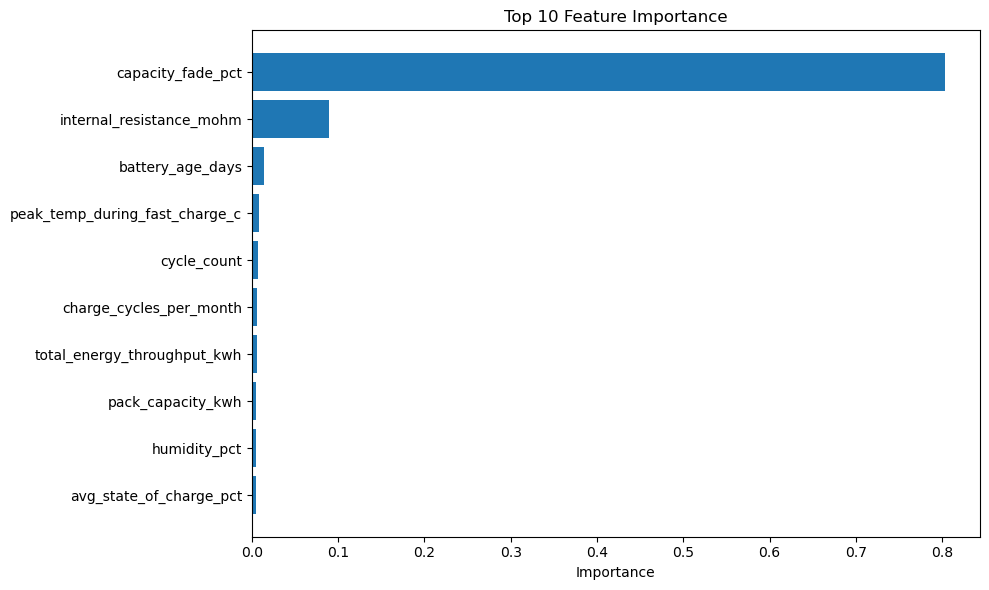

In [91]:
# Feature importance from Decision Tree
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_trained.feature_importances_
}).sort_values('Importance', ascending=False)

print("Top 10 Important Features (from Decision Tree):")
print(feature_importance.head(10))

# Visualize feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_importance.head(10)['Feature'], feature_importance.head(10)['Importance'])
plt.xlabel('Importance')
plt.title('Top 10 Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

---
## 20. Next Steps

### Completed:
- ✓ Data loading and preprocessing
- ✓ All 5 classification models implemented
- ✓ All 6 evaluation metrics calculated
- ✓ Models saved for deployment
- ✓ Test data prepared

### TODO:
1. Create Streamlit app (`app.py` or `streamlit_app.py`)
2. Create `requirements.txt` file
3. Create comprehensive `README.md`
4. Push code to GitHub repository
5. Deploy on Streamlit Community Cloud
6. Test the deployed app
7. Take screenshot on BITS Virtual Lab
8. Prepare final PDF submission

---
## Summary

This notebook has guided you through the complete ML pipeline for Assignment 2:
- Dataset loading and exploration
- Data preprocessing and feature engineering
- Training 5 different classification models
- Calculating 6 evaluation metrics for each model
- Comprehensive model comparison
- Saving models and artifacts for deployment

Good luck with your assignment!